# Evaluation and Validation

So far every model in this project has been judged on one split of the data: train → validation → test. We will use k-fold cross-validation for this project. One split gives one number per metric and cannot tell us how much that number would change if a different period were scored.

This notebook adds k-fold cross-validation on top of the existing pipeline and answers three questions:

| Question | Method |
| --- | --- |
| How well does the model do on weeks it has never seen, and how much does that vary? | **Chronological (forward-chaining) 5-fold CV** — each fold trains on earlier weeks, skips a 7-day gap and scores the next block of weeks. This is how a fraud model is used in practice, so this is the estimate we trust. |
| How much would a classic shuffled k-fold overstate performance on this time-ordered data? | **Shuffled Stratified 5-fold CV**, reported for comparison only (future rows end up in the training folds). |
| How certain are the final test numbers? | **Bootstrap confidence intervals** on the held-out test month, using the fixed final model. |

Two models are compared, both trained with random undersampling (fraud : non-fraud = 1 : 10) as chosen in `Modelling.ipynb`:

- **Baseline XGBoost** — `XGBClassifier(random_state=42, scale_pos_weight=1.0, eval_metric='logloss', n_jobs=-1)`, the constructor used in `Modelling.ipynb` and Fine_Tuning Step 1.
- **Tuned XGBoost** — the same constructor with the hyperparameters chosen in Fine_Tuning Step 2.

Inside **every fold**, the following are rebuilt from the training rows only (same rules as the feature-engineering
notebook and Fine_Tuning Step 2): the 18 frequency-encoded columns, `prev_uid_fraud_count` / `prev_uid_has_fraud`
(training-fold labels at least 7 days old), the category codes and the undersampler. The test month is never used for
cross-validation; it is scored once at the end with the already-fixed final model.

> **Data.** Cross-validation uses the development data = `train.csv` + `val.csv` (2017-12-01 to 2018-04-30). The validation
> period was used to pick the hyperparameters and the threshold, so the cross-validated numbers for the *tuned* model are
> development estimates, not a fully independent test.

## 1. Setup

Run from the repository root after the Fine_Tuning notebooks (Steps 1–4). The tuned hyperparameters, the fixed threshold,
the single-split reference numbers and the fitted model bundles are read from the Fine_Tuning output folders.

In [1]:
# --- Libraries ------------------------------------------------------------------------------------
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)

# --- Settings (change these to re-run the evaluation with a different design) ------------------------
SEED, LABEL = 42, 'isFraud'
EXCLUDE = [LABEL, 'TransactionID', 'TransactionDT', 'TransactionDateTime', 'Transaction_Day', 'uid']  # never model inputs
SAMPLING_RATIO = 0.1       # RandomUnderSampler fraud : non-fraud ratio chosen in Modelling.ipynb (1 : 10)
LABEL_DELAY_DAYS = 7       # a fraud label only becomes "known" 7 days after the transaction (chargeback lag)
GAP_DAYS = 7               # days skipped between training and scoring rows in chronological folds (as in Fine_Tuning Step 2)
N_FOLDS = 5                # folds per cross-validation scheme
FIRST_SCORE_FRAC = 0.40    # the first 40% of development days are only ever used for training
N_BOOTSTRAP = 1000         # resamples of the test split used for the confidence intervals

# --- Paths ----------------------------------------------------------------------------------------
# Resolve the repository from the notebook working directory or BT4012_REPO_DIR.
import os
_start = Path(os.environ.get('BT4012_REPO_DIR', Path.cwd())).resolve()
REPO_DIR = next((p for p in (_start, *_start.parents)
                 if (p / 'Modelling.ipynb').is_file()
                 and (p / 'Fine_Tuning' / 'fine_tuning').is_dir()), None)
if REPO_DIR is None:
    raise FileNotFoundError('Open Jupyter within the repository, or set BT4012_REPO_DIR to its root.')
PROJECT_DIR = REPO_DIR / 'Fine_Tuning' / 'fine_tuning'

# Shared engineered CSVs; no symlinks are required. Root CSVs take precedence.
DATA_DIR = next((p for p in (REPO_DIR, REPO_DIR / 'data')
                 if all((p / f'{s}.csv').is_file() for s in ('train', 'val', 'test'))), REPO_DIR)

# Unset: inspect/use committed artifacts. Set a new name for a fresh reproduction.
RUN_NAME = os.environ.get('BT4012_TUNING_RUN', '').strip()
if RUN_NAME and (RUN_NAME in {'.', '..'} or '/' in RUN_NAME or '\\' in RUN_NAME):
    raise ValueError('BT4012_TUNING_RUN must be a single folder name.')
RUN_DIR = PROJECT_DIR / 'reproductions' / RUN_NAME if RUN_NAME else PROJECT_DIR

FT_DIR = RUN_DIR
OUTPUT_DIR = REPO_DIR / 'evaluation_outputs' if not RUN_NAME else RUN_DIR / 'evaluation_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_PATH = REPO_DIR / 'result.csv' if not RUN_NAME else OUTPUT_DIR / 'result.csv'

def locate(name):
    """Find a split CSV in the repository root or in data/ (same convention as Modelling.ipynb)."""
    for path in (REPO_DIR / name, REPO_DIR / 'data' / name):
        if path.is_file():
            return path
    raise FileNotFoundError(f'{name} not found; run Data_Transformation_Feature_Engineering.ipynb first.')

PATHS = {split: locate(f'{split}.csv') for split in ('train', 'val', 'test')}

def sha256(path):
    """Checksum of a file; stored in the run record so results can be tied to the exact input files."""
    digest = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def show(frame, caption=None, decimals=4):
    """Display a table rounded to `decimals`, with an optional caption printed above it."""
    if caption:
        print(caption)
    display(frame.round(decimals))

# --- Configuration chosen by the Fine_Tuning notebooks ------------------------------------------------
# Step 2 chose the hyperparameters, Step 3 the decision threshold, Step 4 recorded the test results.
try:
    selected = json.loads((FT_DIR / 'step_2_outputs' / 'selected_parameters.json').read_text())
    tuning_run = json.loads((FT_DIR / 'step_2_outputs' / 'tuning_run.json').read_text())
    threshold_selection = json.loads((FT_DIR / 'step_3_outputs' / 'threshold_selection.json').read_text())
    test_comparison = pd.read_csv(FT_DIR / 'step_4_outputs' / 'test_comparison.csv', index_col='stage')
except FileNotFoundError as exc:
    raise FileNotFoundError(f'{exc}\nRun the Fine_Tuning notebooks (Steps 1-4) before this notebook.') from exc

TUNED_PARAMS = selected['parameters']                        # hyperparameters of the tuned model (candidate 15)
FIXED_THRESHOLD = float(threshold_selection['threshold'])    # decision rule of the final model: fraud if score > threshold
VALIDATION_AP = {'Baseline XGBoost': tuning_run['baseline_validation_metrics']['Average precision'],
                 'Tuned XGBoost': tuning_run['selected_validation_metrics']['Average precision']}   # single-split reference
versions = {'python': platform.python_version(), **{p: importlib.metadata.version(p) for p in
            ['numpy', 'pandas', 'scikit-learn', 'imbalanced-learn', 'xgboost', 'joblib']}}
print('Tuned candidate:', selected['candidate_id'], json.dumps(TUNED_PARAMS, sort_keys=True))
print('Fixed threshold:', repr(FIXED_THRESHOLD), '(decision rule: score > threshold)')
print(versions)

Tuned candidate: 15 {"colsample_bytree": 0.85, "learning_rate": 0.05, "max_depth": 6, "min_child_weight": 3, "n_estimators": 400, "reg_alpha": 0.0, "reg_lambda": 3.0, "subsample": 1.0}
Fixed threshold: 0.45939168334007263 (decision rule: score > threshold)
{'python': '3.13.15', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'imbalanced-learn': '0.14.2', 'xgboost': '3.4.1', 'joblib': '1.6.0'}


## 2. Development data as one numeric matrix

`train.csv` and `val.csv` are stacked in time order and converted **once** into a float32 matrix `X_all`:

- numeric columns are copied as they are (±inf → NaN, as in `Modelling.ipynb`);
- the 37 string columns become sorted integer codes, with missing values as their own level — the same idea as the
  `OrdinalEncoder` used in `Modelling.ipynb`; inside a fold, codes that do not occur in the training rows are set to −1
  (the encoder's `unknown_value`);
- the 18 `*_freq` columns and the two `prev_uid_*` columns are placeholders that every fold overwrites.

Working on this matrix instead of re-slicing and re-encoding a 480-column DataFrame per fold makes the per-fold feature
rebuild about ten times faster.

In [2]:
started = time.perf_counter()

# --- Load the development data (train + validation), kept in time order --------------------------------
dev = pd.concat([pd.read_csv(PATHS['train'], low_memory=False), pd.read_csv(PATHS['val'], low_memory=False)], ignore_index=True)
assert dev['TransactionDT'].is_monotonic_increasing and dev['TransactionID'].is_unique and dev[LABEL].isin([0, 1]).all()
dev['TransactionDateTime'] = pd.to_datetime(dev['TransactionDateTime'])
y_dev = dev[LABEL].to_numpy(dtype=np.int64)                      # label of every row (0 / 1)
t_dev = dev['TransactionDT'].to_numpy(dtype=np.int64)            # time of every row (seconds)

# --- Column groups --------------------------------------------------------------------------------
FEATURES = [c for c in dev.columns if c not in EXCLUDE]           # the 482 model inputs, in training order
COL = {c: i for i, c in enumerate(FEATURES)}                      # column name -> position in the matrix
CAT_COLS = [c for c in FEATURES if dev[c].dtype == object]        # the 37 string columns (stored as integer codes)
FREQ_COLS = [c for c in FEATURES if c.endswith('_freq')]          # the 18 frequency encodings (rebuilt inside every fold)
assert len(FEATURES) == 482 and len(CAT_COLS) == 37 and len(FREQ_COLS) == 18

def integer_codes(series, missing_tokens=()):
    """Replace every value of a column by an integer code.

    Codes follow the sorted order of the distinct values. Missing values (and any `missing_tokens`, e.g. the
    'unknown_device' placeholder) share one extra code at the end, so they form their own level.
    Returns (codes, number_of_levels).
    """
    s = series.astype(object)
    s = s.where(s.notna() & ~s.isin(list(missing_tokens)))        # treat the tokens as missing too
    codes, levels = pd.factorize(s, sort=True)                     # missing -> -1
    return np.where(codes < 0, len(levels), codes).astype(np.int32), len(levels) + 1

# --- Build the feature matrix once ---------------------------------------------------------------------
X_all = np.empty((len(dev), len(FEATURES)), dtype=np.float32)
cat_codes = {}                                                      # per string column: the code of every row
for c in FEATURES:
    if c in CAT_COLS:
        cat_codes[c] = integer_codes(dev[c])[0]                    # strings -> codes, missing = its own level
        X_all[:, COL[c]] = cat_codes[c]
    else:
        X_all[:, COL[c]] = dev[c].to_numpy(dtype=np.float32)       # numeric columns as they are
X_all[~np.isfinite(X_all)] = np.nan                                 # +-inf -> NaN, as in Modelling.ipynb
# Codes of the raw column behind each *_freq column, so the frequencies can be recounted inside every fold.
freq_codes = {c: integer_codes(dev[c[:-5]], missing_tokens=('unknown_device',)) for c in FREQ_COLS}

# --- uid history, prepared once for prev_uid_fraud_count --------------------------------------------------
# Rows are sorted by (uid, time). For every row we locate the earlier rows of the same uid whose label is already
# known, i.e. at least LABEL_DELAY_DAYS older. Which labels are allowed to count depends on the fold and is applied
# later in prev_fraud_counts(); the index arrays below never change.
uid = pd.factorize(dev['uid'])[0].astype(np.int64)                              # uid as an integer id per row
uid_order = np.argsort(uid, kind='stable')                                       # row positions sorted by uid, then time
uid_time_key = uid[uid_order] * 10**9 + t_dev[uid_order]                          # one sortable key = (uid, time)
block_starts = np.flatnonzero(np.r_[True, np.diff(uid[uid_order]) != 0])         # where each uid's block of rows begins
uid_first_row = np.repeat(block_starts, np.diff(np.r_[block_starts, len(dev)]))  # start of its uid block, for every row
uid_known_until = np.maximum(np.searchsorted(uid_time_key, uid_time_key - LABEL_DELAY_DAYS * 86400, side='right'),
                             uid_first_row)                                      # rows [uid_first_row, uid_known_until) are the known history

data_sha256 = {split: sha256(path) for split, path in PATHS.items()}
print(f'{len(dev):,} development rows x {len(FEATURES)} features | fraud rate {y_dev.mean():.3%} | '
      f'{dev["TransactionDateTime"].min().date()} to {dev["TransactionDateTime"].max().date()} | '
      f'matrix {X_all.nbytes / 1e9:.1f} GB | {time.perf_counter() - started:.0f}s')

501,214 development rows x 482 features | fraud rate 3.501% | 2017-12-01 to 2018-04-30 | matrix 1.0 GB | 17s


## 3. Folds

- **Chronological:** the first 40% of development days are only used for training; the remaining days form `N_FOLDS`
  consecutive scoring blocks of equal length. Fold *k* trains on every row at least `GAP_DAYS` before block *k* starts
  (expanding window) and scores block *k*. Cuts fall on day boundaries and depend only on time.
- **Shuffled stratified:** `StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)` on the same rows. Each fold
  keeps the overall fraud rate, but its training rows come from the whole period, including days after the scored rows.

In the tables, `fit` = rows a fold trains on, `score` = rows it is evaluated on.

,scheme,fold,fit_rows,fit_fraud_rate,fit_end,score_start,score_end,score_rows,score_fraud,score_fraud_rate
0,chronological,1,204091,0.0301,2018-01-22,2018-01-30,2018-02-16,56796,2416,0.0425
1,chronological,2,259682,0.0330,2018-02-09,2018-02-17,2018-03-06,60061,2108,0.0351
2,chronological,3,312574,0.0338,2018-02-27,2018-03-07,2018-03-25,57374,2298,0.0401
3,chronological,4,376949,0.0341,2018-03-18,2018-03-26,2018-04-12,55465,2179,0.0393
4,chronological,5,434176,0.0351,2018-04-05,2018-04-13,2018-04-30,47780,1570,0.0329
5,stratified_shuffled,1,400971,0.0350,2018-04-30,2017-12-01,2018-04-30,100243,3510,0.0350
6,stratified_shuffled,2,400971,0.0350,2018-04-30,2017-12-01,2018-04-30,100243,3510,0.0350
7,stratified_shuffled,3,400971,0.0350,2018-04-30,2017-12-01,2018-04-30,100243,3510,0.0350
8,stratified_shuffled,4,400971,0.0350,2018-04-30,2017-12-01,2018-04-30,100243,3510,0.0350
9,stratified_shuffled,5,400972,0.0350,2018-04-30,2017-12-01,2018-04-30,100242,3509,0.0350


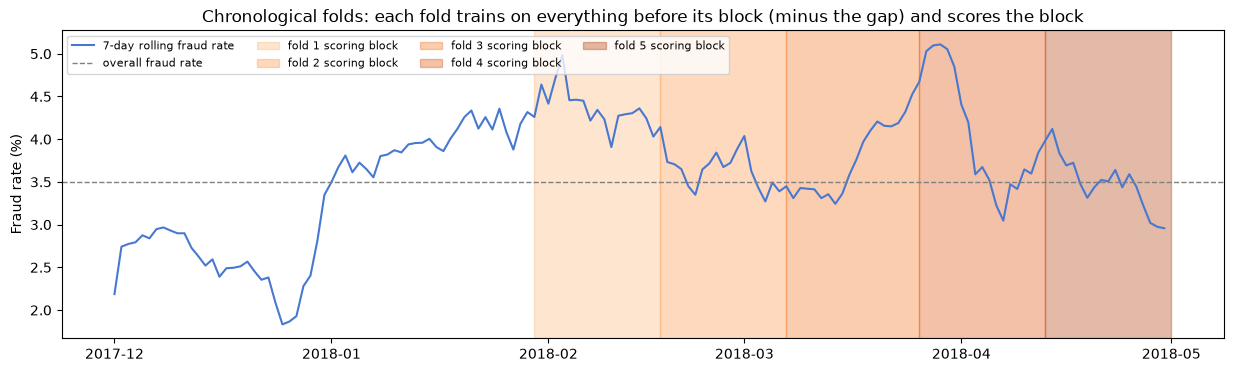

In [3]:
def chronological_folds(n_folds=N_FOLDS, first_score_frac=FIRST_SCORE_FRAC, gap_days=GAP_DAYS):
    """Forward-chaining folds on calendar days.

    Timeline:  [ training-only days (first 40%) | block 1 | block 2 | ... | block n_folds ]
    Fold k scores block k and trains on every row that is at least `gap_days` before block k starts,
    so the training window grows from fold to fold. Returns a list of (train_rows, score_rows) index arrays.
    """
    days = np.unique(t_dev // 86400)                                                   # calendar days present in the data
    edges = np.linspace(round(len(days) * first_score_frac), len(days), n_folds + 1).round().astype(int)
    bounds = [int(days[e]) * 86400 if e < len(days) else (int(days[-1]) + 1) * 86400 for e in edges]   # block edges in seconds
    folds = []
    for start, end in zip(bounds[:-1], bounds[1:]):
        train_rows = np.flatnonzero(t_dev < start - gap_days * 86400)                 # everything before the block, minus the gap
        score_rows = np.flatnonzero((t_dev >= start) & (t_dev < end))                 # the block itself
        folds.append((train_rows, score_rows))
    return folds

# Shuffled stratified folds: same rows, random assignment, fraud rate preserved in every fold (comparison only).
FOLDS = {'chronological': chronological_folds(),
         'stratified_shuffled': list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(y_dev)), y_dev))}

# One line per fold: rows it trains on / scores, their dates and fraud rates
dt = dev['TransactionDateTime']
rows = []
for scheme, folds in FOLDS.items():
    for k, (fit, score) in enumerate(folds, 1):
        rows.append({'scheme': scheme, 'fold': k,
                     'fit_rows': len(fit), 'fit_fraud_rate': y_dev[fit].mean(), 'fit_end': dt.iloc[fit].max().date(),
                     'score_start': dt.iloc[score].min().date(), 'score_end': dt.iloc[score].max().date(),
                     'score_rows': len(score), 'score_fraud': int(y_dev[score].sum()), 'score_fraud_rate': y_dev[score].mean()})
fold_table = pd.DataFrame(rows)
fold_table.to_csv(OUTPUT_DIR / 'fold_definitions.csv', index=False)
show(fold_table)

# Plot: daily fraud rate over the development period, with the chronological scoring blocks shaded
daily = dev.groupby(dt.dt.normalize())[LABEL].mean().mul(100)
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(daily.index, daily.rolling(7, min_periods=1).mean(), color='#4878D0', label='7-day rolling fraud rate')
ax.axhline(100 * y_dev.mean(), color='grey', ls='--', lw=1, label='overall fraud rate')
for (_, row), color in zip(fold_table[fold_table['scheme'] == 'chronological'].iterrows(), plt.cm.Oranges(np.linspace(0.35, 0.85, N_FOLDS))):
    ax.axvspan(pd.Timestamp(row['score_start']), pd.Timestamp(row['score_end']) + pd.Timedelta(days=1), color=color, alpha=0.35,
               label=f"fold {row['fold']} scoring block")
ax.set(title='Chronological folds: each fold trains on everything before its block (minus the gap) and scores the block', ylabel='Fraud rate (%)')
ax.legend(ncol=4, fontsize=8, loc='upper left')
fig.savefig(OUTPUT_DIR / 'chronological_folds.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Per-fold feature rebuild

`prepare_fold` returns the training and scoring matrices of one fold with the fold-dependent columns rebuilt from the
training rows only:

- `*_freq` = share of training rows with the same value (values not seen in training → 0);
- category codes not seen in training → −1;
- `prev_uid_fraud_count` / `prev_uid_has_fraud` = earlier fraud on the same `uid`, counting only training-fold labels
  that are at least `LABEL_DELAY_DAYS` old at the scored transaction.

The check below recomputes these columns by brute force for 100 scoring rows of the first fold of each scheme.

In [4]:
def prev_fraud_counts(fit_idx):
    """For every row: number of earlier fraud cases on the same uid whose label is already known.

    Only labels of training-fold rows (`fit_idx`) may count, and only when the earlier transaction is at least
    LABEL_DELAY_DAYS older than the row itself. Uses the uid history prepared in section 2.
    """
    allowed = np.zeros(len(dev), dtype=np.int64)
    allowed[fit_idx] = y_dev[fit_idx]                                   # labels outside the training rows are unknown (0)
    prefix = np.r_[0, np.cumsum(allowed[uid_order])]                    # running total of known fraud in (uid, time) order
    counts = np.empty(len(dev), dtype=np.int32)
    counts[uid_order] = prefix[uid_known_until] - prefix[uid_first_row] # known fraud between the uid's first row and the cut-off
    return counts

def prepare_fold(fit_idx, score_idx):
    """Training and scoring matrices of one fold, with every fold-dependent column rebuilt from the training rows.

    1. *_freq columns  -> share of training rows with the same value (values unseen in training get 0)
    2. category codes  -> codes not present in the training rows become -1 (the OrdinalEncoder's unknown_value)
    3. prev_uid_*      -> recounted from training-fold labels only (prev_fraud_counts)
    Returns X_fit, X_score, y_fit, y_score.
    """
    X_fit, X_score = X_all[fit_idx], X_all[score_idx]                   # fancy indexing -> independent copies
    for c in FREQ_COLS:                                                 # 1. frequency encodings
        codes, n_levels = freq_codes[c]
        freq = np.bincount(codes[fit_idx], minlength=n_levels) / len(fit_idx)
        X_fit[:, COL[c]], X_score[:, COL[c]] = freq[codes[fit_idx]], freq[codes[score_idx]]
    for c in CAT_COLS:                                                  # 2. unseen categories (training rows are seen by definition)
        seen = np.bincount(cat_codes[c][fit_idx], minlength=cat_codes[c].max() + 1) > 0
        score_codes = cat_codes[c][score_idx]
        X_score[:, COL[c]] = np.where(seen[score_codes], score_codes, -1)
    counts = prev_fraud_counts(fit_idx)                                 # 3. label-history features
    for X, idx in ((X_fit, fit_idx), (X_score, score_idx)):
        X[:, COL['prev_uid_fraud_count']] = counts[idx]
        X[:, COL['prev_uid_has_fraud']] = counts[idx] > 0
    return X_fit, X_score, y_dev[fit_idx], y_dev[score_idx]

# Brute-force check on 100 scoring rows of the first fold of each scheme: recompute the label-history count and one
# frequency column directly from the raw data and compare with prepare_fold's output.
rng = np.random.default_rng(SEED)
card1 = dev['card1'].to_numpy()
for scheme, folds in FOLDS.items():
    fit_idx, score_idx = folds[0]
    assert not np.intersect1d(fit_idx, score_idx).size                   # training and scoring rows never overlap
    _, X_score, _, _ = prepare_fold(fit_idx, score_idx)
    counts, in_fit = prev_fraud_counts(fit_idx), np.zeros(len(dev), dtype=bool)
    in_fit[fit_idx] = True
    for pos in rng.choice(len(score_idx), 100, replace=False):
        i = score_idx[pos]
        history = in_fit & (uid == uid[i]) & (t_dev <= t_dev[i] - LABEL_DELAY_DAYS * 86400)   # same uid, training row, old enough
        assert y_dev[history].sum() == counts[i]
        assert np.isclose(X_score[pos, COL['card1_freq']], np.mean(card1[fit_idx] == card1[i]))
    print(f'{scheme:20s}: label-history and frequency rebuild verified on 100 scoring rows')

chronological       : label-history and frequency rebuild verified on 100 scoring rows


stratified_shuffled : label-history and frequency rebuild verified on 100 scoring rows


## 5. Models, metrics and the cross-validation run

Per fold we record average precision (PR-AUC, the project's primary metric) and ROC AUC, the precision / recall / F1 /
false-positive rate at the default 0.5 and at the fixed Step 3 threshold (rule `score > threshold`), and the threshold
that maximises F1 *within the scoring block*. The last one looks ahead, so it is not a performance claim; it only shows
whether the threshold chosen on the validation month is typical of other periods.

In [5]:
def make_models():
    """The two models compared: library-default XGBoost (as in Modelling.ipynb) and the Fine_Tuning candidate."""
    baseline = XGBClassifier(random_state=SEED, scale_pos_weight=1.0, eval_metric='logloss', n_jobs=-1)
    return {'Baseline XGBoost': baseline, 'Tuned XGBoost': clone(baseline).set_params(**TUNED_PARAMS)}

def metrics_at(y, score, threshold):
    """Precision, recall, F1 and false-positive rate when rows with score > threshold are flagged as fraud."""
    pred, pos = score > threshold, y == 1
    tp, fp, fn = np.sum(pred & pos), np.sum(pred & ~pos), np.sum(~pred & pos)
    return {'precision': tp / max(tp + fp, 1), 'recall': tp / (tp + fn), 'f1': 2 * tp / (2 * tp + fp + fn), 'fpr': fp / np.sum(~pos)}

def best_f1_threshold(y, score):
    """The threshold that would have given the highest F1 on these rows (strict rule score > t).

    Rows are sorted by score. `positives[i]` = fraud cases among the i lowest scores, so a threshold that excludes
    the lowest `excluded` rows gives TP = total fraud - positives[excluded] and alerts = n - excluded, and
    F1 = 2 TP / (alerts + total fraud). All distinct scores are evaluated at once.
    """
    order = np.argsort(score, kind='stable')
    s, positives = score[order], np.r_[0, np.cumsum(y[order])]
    thresholds = np.unique(s)
    excluded = np.searchsorted(s, thresholds, side='right')            # rows with score <= t, for every candidate t
    f1 = 2 * (positives[-1] - positives[excluded]) / (len(y) - excluded + positives[-1])
    return float(thresholds[f1.argmax()]), float(f1.max())

def evaluate_scores(y, score):
    """All per-fold metrics of one model: ranking metrics, metrics at 0.5 and at the fixed threshold, best-F1 threshold."""
    out = {'average_precision': average_precision_score(y, score), 'roc_auc': roc_auc_score(y, score)}
    for tag, threshold in (('0.5', 0.5), ('fixed', FIXED_THRESHOLD)):
        out.update({f'{k}@{tag}': v for k, v in metrics_at(y, score, threshold).items()})
    out['best_f1_threshold'], out['best_f1'] = best_f1_threshold(y, score)
    return out

# --- Cross-validation loop -------------------------------------------------------------------------------
# For every scheme and fold: rebuild the features -> undersample the training rows -> fit both models -> score the fold.
records, fold_scores = [], {}
cv_started = time.perf_counter()
for scheme, folds in FOLDS.items():
    for k, (fit_idx, score_idx) in enumerate(folds, 1):
        X_fit, X_score, y_fit, y_score = prepare_fold(fit_idx, score_idx)
        X_fit, y_fit = RandomUnderSampler(sampling_strategy=SAMPLING_RATIO, random_state=SEED).fit_resample(X_fit, y_fit)
        for name, model in make_models().items():
            t0 = time.perf_counter()
            score = model.fit(X_fit, y_fit).predict_proba(X_score)[:, 1].astype(np.float64)
            records.append({'scheme': scheme, 'fold': k, 'model': name, 'train_rows': len(y_fit), 'score_rows': len(y_score),
                            'score_fraud': int(y_score.sum()), 'seconds': time.perf_counter() - t0, **evaluate_scores(y_score, score)})
            fold_scores[(scheme, k, name)] = (y_score, score)                       # kept for the precision-recall curves
            r = records[-1]
            print(f"{scheme:20s} fold {k} | {name:17s} | AP={r['average_precision']:.4f} ROC AUC={r['roc_auc']:.4f} "
                  f"F1@fixed={r['f1@fixed']:.4f} F1@0.5={r['f1@0.5']:.4f} | best-F1 thr={r['best_f1_threshold']:.3f} | {r['seconds']:.0f}s", flush=True)
cv = pd.DataFrame(records)
cv.to_csv(OUTPUT_DIR / 'cv_fold_results.csv', index=False)
print(f'{len(cv)} fits in {time.perf_counter() - cv_started:.0f}s')

chronological        fold 1 | Baseline XGBoost  | AP=0.6829 ROC AUC=0.9273 F1@fixed=0.6436 F1@0.5=0.6476 | best-F1 thr=0.565 | 1s


chronological        fold 1 | Tuned XGBoost     | AP=0.6901 ROC AUC=0.9351 F1@fixed=0.6454 F1@0.5=0.6481 | best-F1 thr=0.522 | 3s


chronological        fold 2 | Baseline XGBoost  | AP=0.6072 ROC AUC=0.9124 F1@fixed=0.5829 F1@0.5=0.5849 | best-F1 thr=0.529 | 1s


chronological        fold 2 | Tuned XGBoost     | AP=0.6471 ROC AUC=0.9229 F1@fixed=0.6190 F1@0.5=0.6187 | best-F1 thr=0.404 | 3s


chronological        fold 3 | Baseline XGBoost  | AP=0.6449 ROC AUC=0.9284 F1@fixed=0.6108 F1@0.5=0.6101 | best-F1 thr=0.487 | 1s


chronological        fold 3 | Tuned XGBoost     | AP=0.6744 ROC AUC=0.9383 F1@fixed=0.6338 F1@0.5=0.6291 | best-F1 thr=0.386 | 3s


... (11 outputs left out)

stratified_shuffled  fold 4 | Tuned XGBoost     | AP=0.7672 ROC AUC=0.9558 F1@fixed=0.7204 F1@0.5=0.7228 | best-F1 thr=0.525 | 4s


stratified_shuffled  fold 5 | Baseline XGBoost  | AP=0.7772 ROC AUC=0.9622 F1@fixed=0.7260 F1@0.5=0.7286 | best-F1 thr=0.525 | 1s


stratified_shuffled  fold 5 | Tuned XGBoost     | AP=0.7618 ROC AUC=0.9588 F1@fixed=0.7150 F1@0.5=0.7154 | best-F1 thr=0.482 | 4s


20 fits in 53s


## 6. Results

The standard deviation shows how much a metric moves from one scoring period (or random partition) to the next; with
five folds it is a spread, not a confidence interval. Because both models score the same rows in each fold, the
tuned − baseline differences are paired; with only five (overlapping) folds the paired *t*-test p-value is indicative,
and the number of folds won is the more honest summary.

In [6]:
METRICS = ['average_precision', 'roc_auc', 'f1@fixed', 'precision@fixed', 'recall@fixed', 'f1@0.5', 'best_f1_threshold']
show(cv[['scheme', 'fold', 'model', 'score_rows', 'score_fraud'] + METRICS], 'Per-fold results')

# Mean and standard deviation of every metric across the folds, per scheme and model
summary = cv.groupby(['scheme', 'model'])[METRICS].agg(['mean', 'std'])
summary.columns = [f'{m}_{s}' for m, s in summary.columns]
summary.to_csv(OUTPUT_DIR / 'cv_summary.csv')
show(pd.DataFrame({m: summary[f'{m}_mean'].map('{:.4f}'.format) + ' ± ' + summary[f'{m}_std'].map('{:.4f}'.format) for m in METRICS}),
     'Mean ± standard deviation across folds')

# Paired comparison: in every fold both models score the same rows, so we look at tuned minus baseline fold by fold
rows = []
for scheme in FOLDS:
    sub = cv[cv['scheme'] == scheme].set_index(['model', 'fold'])
    for m in METRICS[:4]:
        tuned, base = sub.loc['Tuned XGBoost', m], sub.loc['Baseline XGBoost', m]   # one value per fold, same fold order
        rows.append({'scheme': scheme, 'metric': m, 'mean_difference_tuned_minus_baseline': (tuned - base).mean(),
                     'folds_tuned_better': int((tuned.to_numpy() > base.to_numpy()).sum()),
                     'paired_t_p_value': stats.ttest_rel(tuned, base).pvalue})
paired = pd.DataFrame(rows)
paired.to_csv(OUTPUT_DIR / 'cv_paired_comparison.csv', index=False)
show(paired, 'Paired comparison: tuned vs baseline on the same folds')

Per-fold results


,scheme,fold,model,score_rows,score_fraud,average_precision,roc_auc,f1@fixed,precision@fixed,recall@fixed,f1@0.5,best_f1_threshold
0,chronological,1,Baseline XGBoost,56796,2416,0.6829,0.9273,0.6436,0.7329,0.5737,0.6476,0.5653
1,chronological,1,Tuned XGBoost,56796,2416,0.6901,0.9351,0.6454,0.7459,0.5687,0.6481,0.5216
2,chronological,2,Baseline XGBoost,60061,2108,0.6072,0.9124,0.5829,0.6718,0.5147,0.5849,0.5294
3,chronological,2,Tuned XGBoost,60061,2108,0.6471,0.9229,0.6190,0.7488,0.5275,0.6187,0.4042
4,chronological,3,Baseline XGBoost,57374,2298,0.6449,0.9284,0.6108,0.7021,0.5405,0.6101,0.4871
5,chronological,3,Tuned XGBoost,57374,2298,0.6744,0.9383,0.6338,0.7835,0.5322,0.6291,0.3862
6,chronological,4,Baseline XGBoost,55465,2179,0.6821,0.9293,0.6471,0.7051,0.5980,0.6510,0.6246
7,chronological,4,Tuned XGBoost,55465,2179,0.6972,0.9381,0.6615,0.7331,0.6026,0.6624,0.5822
8,chronological,5,Baseline XGBoost,47780,1570,0.6543,0.9382,0.6244,0.6884,0.5713,0.6188,0.4486
9,chronological,5,Tuned XGBoost,47780,1570,0.6658,0.9426,0.6307,0.7179,0.5624,0.6287,0.5513


Mean ± standard deviation across folds


average_precision          roc_auc         f1@fixed  precision@fixed     recall@fixed           f1@0.5 best_f1_threshold
scheme              model                                                                                                                                    
chronological       Baseline XGBoost   0.6543 ± 0.0312  0.9271 ± 0.0093  0.6218 ± 0.0263  0.7001 ± 0.0226  0.5596 ± 0.0324  0.6225 ± 0.0275   0.5310 ± 0.0683
                    Tuned XGBoost      0.6749 ± 0.0199  0.9354 ± 0.0075  0.6381 ± 0.0161  0.7458 ± 0.0243  0.5587 ± 0.0305  0.6374 ± 0.0176   0.4891 ± 0.0886
stratified_shuffled Baseline XGBoost   0.7797 ± 0.0024  0.9620 ± 0.0019  0.7270 ± 0.0033  0.7659 ± 0.0046  0.6919 ± 0.0046  0.7300 ± 0.0034   0.5397 ± 0.0360
                    Tuned XGBoost      0.7654 ± 0.0028  0.9583 ± 0.0014  0.7169 ± 0.0027  0.7838 ± 0.0053  0.6606 ± 0.0054  0.7192 ± 0.0046   0.5163 ± 0.0414

Paired comparison: tuned vs baseline on the same folds


,scheme,metric,mean_difference_tuned_minus_baseline,folds_tuned_better,paired_t_p_value
0,chronological,average_precision,0.0206,5,0.0274
1,chronological,roc_auc,0.0083,5,0.0015
2,chronological,f1@fixed,0.0163,5,0.0566
3,chronological,precision@fixed,0.0458,5,0.0305
4,stratified_shuffled,average_precision,-0.0143,0,0.0007
5,stratified_shuffled,roc_auc,-0.0037,0,0.0003
6,stratified_shuffled,f1@fixed,-0.0101,0,0.0005
7,stratified_shuffled,precision@fixed,0.0179,5,0.0004


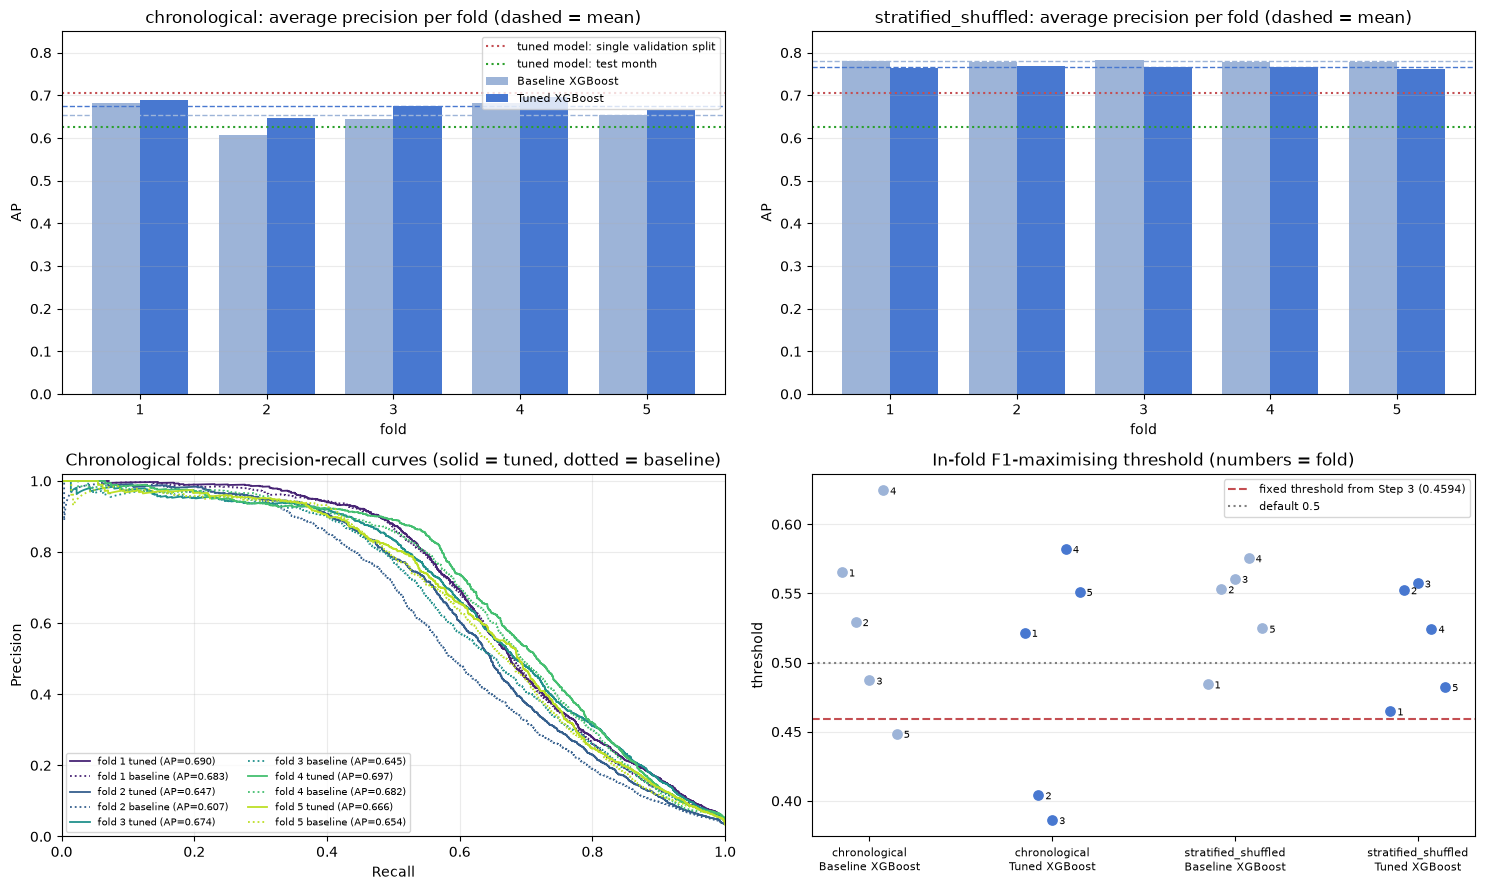

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
colors = {'Baseline XGBoost': '#9DB4D8', 'Tuned XGBoost': '#4878D0'}

# Row 1: average precision per fold, one panel per scheme
for ax, scheme in zip(axes[0], FOLDS):
    for i, (name, color) in enumerate(colors.items()):
        s = cv[(cv['scheme'] == scheme) & (cv['model'] == name)]
        ax.bar(s['fold'] + (i - 0.5) * 0.38, s['average_precision'], 0.38, label=name, color=color)
        ax.axhline(s['average_precision'].mean(), color=color, ls='--', lw=1)
    ax.axhline(VALIDATION_AP['Tuned XGBoost'], color='#C44E52', ls=':', label='tuned model: single validation split')
    ax.axhline(test_comparison.loc['Step 2 tuned model at 0.5', 'average_precision'], color='#2CA02C', ls=':', label='tuned model: test month')
    ax.set(title=f'{scheme}: average precision per fold (dashed = mean)', xlabel='fold', ylabel='AP', ylim=(0, 0.85), xticks=range(1, N_FOLDS + 1))
    ax.grid(axis='y', alpha=0.25)
axes[0, 0].legend(fontsize=8)

# Row 2 left: precision-recall curves of the chronological folds
ax = axes[1, 0]
for k, color in enumerate(plt.cm.viridis(np.linspace(0.1, 0.9, N_FOLDS)), 1):
    for name, ls in (('Tuned XGBoost', '-'), ('Baseline XGBoost', ':')):
        y_k, s_k = fold_scores[('chronological', k, name)]
        p, r, _ = precision_recall_curve(y_k, s_k)
        ax.plot(r, p, ls=ls, color=color, lw=1.3, label=f'fold {k} {name.split()[0].lower()} (AP={average_precision_score(y_k, s_k):.3f})')
ax.set(title='Chronological folds: precision-recall curves (solid = tuned, dotted = baseline)', xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.25)

# Row 2 right: where F1 peaks in each fold vs the fixed threshold
ax = axes[1, 1]
for x, (scheme, name) in enumerate([(s, m) for s in FOLDS for m in colors]):
    s = cv[(cv['scheme'] == scheme) & (cv['model'] == name)].sort_values('fold')
    xs = x + np.linspace(-0.15, 0.15, N_FOLDS)
    ax.scatter(xs, s['best_f1_threshold'], color=colors[name], s=45, zorder=3)
    for xi, (_, r) in zip(xs, s.iterrows()):
        ax.annotate(str(int(r['fold'])), (xi, r['best_f1_threshold']), textcoords='offset points', xytext=(5, -3), fontsize=7)
ax.axhline(FIXED_THRESHOLD, color='#C44E52', ls='--', label=f'fixed threshold from Step 3 ({FIXED_THRESHOLD:.4f})')
ax.axhline(0.5, color='grey', ls=':', label='default 0.5')
ax.set_xticks(range(4))
ax.set_xticklabels([f'{s}\n{m}' for s in FOLDS for m in colors], fontsize=8)
ax.set(title='In-fold F1-maximising threshold (numbers = fold)', ylabel='threshold')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'cv_results.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Bootstrap confidence intervals on the held-out test month

The final model (Fine_Tuning Step 4 bundle: tuned XGBoost + encoder + fixed threshold) and the Step 1 baseline bundle score
the test split once; nothing is refitted or re-selected. The test rows are then resampled with replacement `N_BOOTSTRAP`
times. The 2.5th and 97.5th percentiles of the resampled metrics give a 95% interval, and because every configuration is
evaluated on the same resampled rows, the differences between configurations are paired.

In [8]:
# --- Score the test split once with the saved model bundles ------------------------------------------------
baseline_bundle = joblib.load(FT_DIR / 'baseline_outputs' / 'baseline_bundle.joblib')        # Step 1 model
final_bundle = joblib.load(FT_DIR / 'step_4_outputs' / 'final_model_bundle.joblib')         # tuned model + threshold
assert final_bundle['threshold_rule'] == '>' and np.isclose(final_bundle['threshold'], FIXED_THRESHOLD)

def bundle_scores(frame, bundle):
    """Fraud scores for already-engineered rows, using the bundle's own encoder and feature order."""
    X = frame[bundle['features']].replace([np.inf, -np.inf], np.nan)
    X[bundle['categorical_columns']] = bundle['encoder'].transform(X[bundle['categorical_columns']].astype(str))
    return bundle['model'].predict_proba(X)[:, 1].astype(np.float64)

test = pd.read_csv(PATHS['test'], low_memory=False)
assert test['TransactionDT'].min() > t_dev.max(), 'the test split must be strictly later than the development data'
y_test = test[LABEL].to_numpy(dtype=np.int64)
test_scores = {'Baseline XGBoost': bundle_scores(test, baseline_bundle), 'Tuned XGBoost': bundle_scores(test, final_bundle)}
del test

# --- The three configurations compared: baseline at 0.5, tuned at 0.5, tuned at the fixed threshold ------------
FINAL = f'Final @ {FIXED_THRESHOLD:.4f}'
CONFIGS = {'Baseline @ 0.5': ('Baseline XGBoost', 0.5), 'Tuned @ 0.5': ('Tuned XGBoost', 0.5), FINAL: ('Tuned XGBoost', FIXED_THRESHOLD)}

def test_metrics(idx):
    """Metrics of all three configurations on the test rows `idx`, as a table (configuration x metric)."""
    y = y_test[idx]
    ranking = {m: (average_precision_score(y, s[idx]), roc_auc_score(y, s[idx])) for m, s in test_scores.items()}   # per model
    return pd.DataFrame({label: {'average_precision': ranking[m][0], 'roc_auc': ranking[m][1], **metrics_at(y, test_scores[m][idx], thr)}
                         for label, (m, thr) in CONFIGS.items()}).T

point = test_metrics(np.arange(len(y_test)))                                   # metrics on the full test split
assert np.isclose(point.loc[FINAL, 'average_precision'], test_comparison.loc['Final model at fixed threshold', 'average_precision'])
print('Recomputed test metrics match Fine_Tuning Step 4.')

# --- Bootstrap: resample the test rows with replacement and recompute the whole table each time -------------------
t0, rng = time.perf_counter(), np.random.default_rng(SEED)
boot = np.stack([test_metrics(rng.integers(0, len(y_test), len(y_test))).to_numpy() for _ in range(N_BOOTSTRAP)])
# boot[b, i, j] = metric j of configuration i in replicate b
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)                                # 95% percentile interval per cell of the table
test_ci = pd.DataFrame({'estimate': point.stack(), 'ci_low': pd.DataFrame(lo, point.index, point.columns).stack(),
                        'ci_high': pd.DataFrame(hi, point.index, point.columns).stack()}).rename_axis(['configuration', 'metric'])
test_ci.to_csv(OUTPUT_DIR / 'test_bootstrap_ci.csv')
print(f'{N_BOOTSTRAP} bootstrap replicates of {len(y_test):,} test rows ({int(y_test.sum()):,} fraud) in {time.perf_counter() - t0:.0f}s')
show(test_ci, 'Test metrics with 95% bootstrap intervals')

# --- Paired differences: every replicate uses the same resampled rows for all configurations -----------------------
CONTRASTS = [('Tuned @ 0.5', 'Baseline @ 0.5', 'average_precision', 'Hyperparameter tuning: AP'),
             ('Tuned @ 0.5', 'Baseline @ 0.5', 'roc_auc', 'Hyperparameter tuning: ROC AUC'),
             ('Tuned @ 0.5', 'Baseline @ 0.5', 'f1', 'Hyperparameter tuning: F1 at 0.5'),
             (FINAL, 'Tuned @ 0.5', 'f1', 'Threshold tuning: F1 vs 0.5'),
             (FINAL, 'Tuned @ 0.5', 'recall', 'Threshold tuning: recall vs 0.5'),
             (FINAL, 'Tuned @ 0.5', 'precision', 'Threshold tuning: precision vs 0.5'),
             (FINAL, 'Baseline @ 0.5', 'f1', 'Final system vs original baseline: F1')]
rows = []
for a, b, m, what in CONTRASTS:
    i_a, i_b, j = point.index.get_loc(a), point.index.get_loc(b), point.columns.get_loc(m)
    d = boot[:, i_a, j] - boot[:, i_b, j]                                        # a minus b in every replicate
    rows.append({'comparison': what, 'difference': point.loc[a, m] - point.loc[b, m], 'ci_low': np.percentile(d, 2.5),
                 'ci_high': np.percentile(d, 97.5), 'share_of_replicates_positive': (d > 0).mean()})
test_diff = pd.DataFrame(rows)
test_diff.to_csv(OUTPUT_DIR / 'test_bootstrap_differences.csv', index=False)
show(test_diff, 'Paired differences (an interval that excludes 0 means the change is larger than test-set sampling noise)')

Recomputed test metrics match Fine_Tuning Step 4.


1000 bootstrap replicates of 89,326 test rows (3,114 fraud) in 32s
Test metrics with 95% bootstrap intervals


estimate  ci_low  ci_high
configuration  metric                                      
Baseline @ 0.5 average_precision    0.5942  0.5757   0.6120
               roc_auc              0.9060  0.8993   0.9120
               precision            0.6661  0.6470   0.6859
               recall               0.5177  0.5003   0.5354
               f1                   0.5826  0.5668   0.5980
               fpr                  0.0094  0.0088   0.0100
Tuned @ 0.5    average_precision    0.6263  0.6089   0.6422
               roc_auc              0.9182  0.9120   0.9240
               precision            0.7192  0.7007   0.7385
               recall               0.5273  0.5100   0.5436
               f1                   0.6085  0.5932   0.6234
               fpr                  0.0074  0.0068   0.0080
Final @ 0.4594 average_precision    0.6263  0.6089   0.6422
               roc_auc              0.9182  0.9120   0.9240
               precision            0.6878  0.6690   0.7070
               recall               0.5446  0.5269   0.5612
               f1                   0.6079  0.5930   0.6226
               fpr                  0.0089  0.0083   0.0096

Paired differences (an interval that excludes 0 means the change is larger than test-set sampling noise)


,comparison,difference,ci_low,ci_high,share_of_replicates_positive
0,Hyperparameter tuning: AP,0.0320,0.0255,0.0385,1.000
1,Hyperparameter tuning: ROC AUC,0.0123,0.0103,0.0144,1.000
2,Hyperparameter tuning: F1 at 0.5,0.0259,0.0172,0.0345,1.000
3,Threshold tuning: F1 vs 0.5,-0.0006,-0.0051,0.0040,0.397
4,Threshold tuning: recall vs 0.5,0.0173,0.0128,0.0220,1.000
5,Threshold tuning: precision vs 0.5,-0.0315,-0.0384,-0.0246,0.000
6,Final system vs original baseline: F1,0.0253,0.0170,0.0343,1.000


## 8. Putting it all together

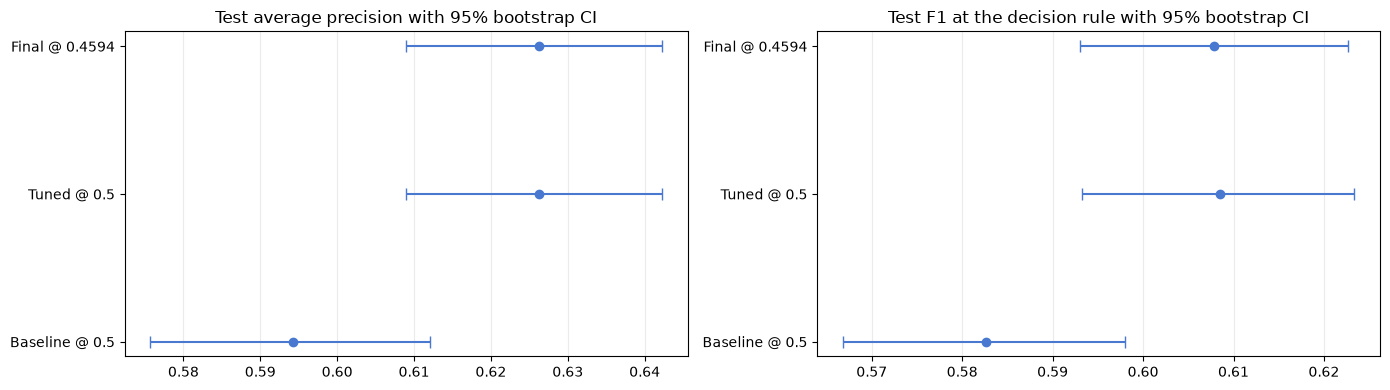

model,Baseline XGBoost,Tuned XGBoost
CV chronological AP,0.6543 ± 0.0312,0.6749 ± 0.0199
CV stratified_shuffled AP,0.7797 ± 0.0024,0.7654 ± 0.0028
Validation split AP,0.7058,0.7066
Test decision rule,Baseline @ 0.5,Final @ 0.4594
Test AP [95% CI],"0.5942 [0.5757, 0.6120]","0.6263 [0.6089, 0.6422]"
Test F1 at decision rule [95% CI],"0.5826 [0.5668, 0.5980]","0.6079 [0.5930, 0.6226]"


Tuned XGBoost AP: chronological CV 0.6749 ± 0.0199 | shuffled CV 0.7654 ± 0.0028 | optimism of shuffled k-fold: +0.0905
Saved: ['chronological_folds.png', 'consolidated_summary.csv', 'cv_fold_results.csv', 'cv_paired_comparison.csv', 'cv_results.png', 'cv_summary.csv', 'evaluation_run.json', 'fold_definitions.csv', 'test_bootstrap_ci.csv', 'test_bootstrap_ci.png', 'test_bootstrap_differences.csv']


In [9]:
# --- Plot: test metrics with their 95% intervals ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric, title in zip(axes, ('average_precision', 'f1'), ('Test average precision', 'Test F1 at the decision rule')):
    sub = test_ci.xs(metric, level='metric')
    ax.errorbar(sub['estimate'], range(len(sub)), xerr=[sub['estimate'] - sub['ci_low'], sub['ci_high'] - sub['estimate']],
                fmt='o', color='#4878D0', capsize=4)
    ax.set(yticks=range(len(sub)), yticklabels=sub.index, title=f'{title} with 95% bootstrap CI')
    ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'test_bootstrap_ci.png', dpi=150, bbox_inches='tight')
plt.show()

# --- One table: cross-validation vs the single validation split vs the test split -------------------------------
rows = []
for name, config in (('Baseline XGBoost', 'Baseline @ 0.5'), ('Tuned XGBoost', FINAL)):
    row = {'model': name}
    for scheme in FOLDS:
        s = summary.loc[(scheme, name)]
        row[f'CV {scheme} AP'] = f"{s['average_precision_mean']:.4f} ± {s['average_precision_std']:.4f}"
    row['Validation split AP'] = f'{VALIDATION_AP[name]:.4f}'
    row['Test decision rule'] = config
    for metric, label in (('average_precision', 'Test AP [95% CI]'), ('f1', 'Test F1 at decision rule [95% CI]')):
        e = test_ci.loc[(config, metric)]
        row[label] = f"{e['estimate']:.4f} [{e['ci_low']:.4f}, {e['ci_high']:.4f}]"
    rows.append(row)
consolidated = pd.DataFrame(rows).set_index('model').T
consolidated.to_csv(OUTPUT_DIR / 'consolidated_summary.csv')
display(consolidated)

chrono, shuffled = summary.loc[('chronological', 'Tuned XGBoost')], summary.loc[('stratified_shuffled', 'Tuned XGBoost')]
print(f"Tuned XGBoost AP: chronological CV {chrono['average_precision_mean']:.4f} ± {chrono['average_precision_std']:.4f} | "
      f"shuffled CV {shuffled['average_precision_mean']:.4f} ± {shuffled['average_precision_std']:.4f} | "
      f"optimism of shuffled k-fold: {shuffled['average_precision_mean'] - chrono['average_precision_mean']:+.4f}")

# --- Save a record of this run: settings, package versions, data checksums and all summary tables ----------------
json.dump({'evaluated_at': pd.Timestamp.now().isoformat(), 'versions': versions, 'data_sha256': data_sha256,
           'config': {'seed': SEED, 'n_folds': N_FOLDS, 'first_score_frac': FIRST_SCORE_FRAC, 'gap_days': GAP_DAYS,
                      'label_delay_days': LABEL_DELAY_DAYS, 'sampling_ratio': SAMPLING_RATIO, 'n_bootstrap': N_BOOTSTRAP,
                      'tuned_candidate': selected['candidate_id'], 'tuned_parameters': TUNED_PARAMS, 'fixed_threshold': FIXED_THRESHOLD},
           'cv_summary': summary.reset_index().to_dict('records'), 'paired_comparison': paired.to_dict('records'),
           'test_bootstrap_ci': test_ci.reset_index().to_dict('records'), 'test_bootstrap_differences': test_diff.to_dict('records')},
          open(OUTPUT_DIR / 'evaluation_run.json', 'w'), indent=2, default=lambda v: v.item() if isinstance(v, np.generic) else str(v))
print('Saved:', sorted(p.name for p in OUTPUT_DIR.iterdir()))

## 9. Interpretation

**How to read the three estimates**

- *Chronological k-fold* is the realistic estimate. Every fold scores weeks the model has never seen, after a 7-day gap,
  with all label-based and frequency features rebuilt from the training weeks only. The spread across folds shows how
  much performance depends on *which weeks* are scored — something one validation month cannot show.
- *Shuffled k-fold* lets future rows into training and lets the frequency encodings see the whole period. The gap between
  it and the chronological estimate is how much a classic k-fold would have overstated performance on this data.
- *Test month with bootstrap intervals* is the one-shot check of the fixed final system. The paired differences show
  which tuning steps changed more than test-set sampling noise.

**Findings of this run** (2026-10-23, pinned `requirements-tuning.txt` environment; exact numbers are in the tables above
and in `evaluation_outputs/`)

1. **Hyperparameter tuning helps, and the gain holds across periods.** Under chronological CV the tuned model beats the
   baseline in **5 of 5 folds** (AP 0.675 ± 0.020 vs 0.654 ± 0.031, average gain +0.021; ROC AUC +0.008; F1 at the fixed
   threshold +0.016). The test month shows the same gain, with an interval that excludes zero (AP +0.032,
   95% CI [+0.026, +0.039]; F1 at 0.5 +0.026, CI [+0.017, +0.035]).
2. **Classic shuffled k-fold gives the wrong picture.** It inflates AP by about **+0.09** (0.765 vs 0.675 for the tuned
   model), shows an unrealistically small spread (± 0.003), and even **ranks the two models the wrong way round**: the
   default-parameter baseline "wins" all 5 shuffled folds (AP 0.780 vs 0.765). A likely reason: in a shuffled split the
   same cards and UIDs appear in both the training and the scoring folds. The default settings (learning rate 0.3, no
   column subsampling) learn fast and are rewarded for memorising them. The tuned settings (learning rate 0.05,
   `colsample_bytree` 0.85, stronger L2, `min_child_weight` 3) learn more slowly and are the ones that carry forward in
   time. Choosing a model on shuffled folds would have picked the wrong one.
3. **Results vary a lot from period to period.** Across the chronological folds, tuned-model AP runs from 0.647
   (17 Feb – 6 Mar) to 0.697 (26 Mar – 12 Apr). That swing of about 0.05 is larger than the hyperparameter effect in any
   single period. The validation month (0.707) sits at the optimistic end of this range and the test month (0.626) below
   it, so a single split can over- or under-state the model. The fair statement is: "AP ≈ 0.67 ± 0.02 on held-out future
   weeks, 0.63 on the May test month".
4. **The F1-maximising threshold is not stable.** Within the chronological folds, the F1 peak of the tuned model moves
   between 0.39 and 0.58 (mean 0.49 ± 0.09). The threshold picked on the validation month in Step 3 (0.4594 in this run,
   0.3574 in the recorded run, with almost the same validation F1) is just one draw from that range. On the test month
   it changes F1 by −0.0006 (CI [−0.005, +0.004]) compared with 0.5 — a trade of precision for recall (+1.7 pp recall,
   −3.2 pp precision), not an improvement. The operating point should be set from review capacity or from the cost of a
   missed fraud versus a false alarm, not from one month's F1 peak.
5. **Final system on the test month, with uncertainty:** AP 0.626 [0.609, 0.642], ROC AUC 0.918 [0.912, 0.924],
   precision 0.688 [0.669, 0.707], recall 0.545 [0.527, 0.561], F1 0.608 [0.593, 0.623] at the fixed threshold. F1 is
   +0.025 [+0.017, +0.034] above the original baseline at 0.5.

**Limitations.** The same as in the Fine_Tuning README: the development / test boundaries were chosen with knowledge of
fraud rates; the validation period was used to pick the model and the threshold (so the tuned model's cross-validated
numbers are development estimates); and the scores are not calibrated probabilities. The chronological folds also share
training data, so their standard deviation is a descriptive spread, not a confidence interval.

## 10. Make predictions and create the results file

`write_result` scores the input file with the final model and writes one row per transaction:

| Column | Meaning |
| --- | --- |
| `TransactionID` | transaction identifier |
| `fraud_score` | model probability of fraud |
| `is_fraud_pred` | 1 if `fraud_score` > threshold, else 0 |
| `isFraud` | the true label, only when the input file has one |

The model, encoder, feature order and threshold all come from the Fine_Tuning Step 4 bundle. The file is read in chunks
and only the needed columns are loaded, so large inputs work too. This cell only needs the Setup cell (section 1) to have
been run first.

In [10]:
from sklearn.metrics import f1_score, precision_score, recall_score

BUNDLE_PATH = FT_DIR / 'step_4_outputs' / 'final_model_bundle.joblib'     # final model + encoder + feature order + threshold

def prepare_features(frame, bundle):
    """Turn engineered rows into exactly the matrix the model was trained on (same steps as Modelling.ipynb)."""
    X = frame.loc[:, bundle['features']].replace([np.inf, -np.inf], np.nan)   # training column order; +-inf -> NaN
    cats = bundle['categorical_columns']
    X[cats] = bundle['encoder'].transform(X[cats].astype(str))                  # strings -> codes; unseen values -> -1
    return X

def write_result(input_csv, output_csv='result.csv', bundle_path=BUNDLE_PATH, threshold=None, chunk_rows=100_000):
    """Score every row of an engineered CSV and write the predictions to `output_csv`.

    Output columns: TransactionID, fraud_score, is_fraud_pred (1 if fraud_score > threshold) and, when the input has
    labels, isFraud. The file is read in chunks and only the needed columns are loaded, so large inputs work too.
    Returns the full result table and prints a short summary (with precision / recall / F1 / AP if labels exist).
    """
    bundle = joblib.load(bundle_path)
    threshold = float(bundle['threshold'] if threshold is None else threshold)

    header = pd.read_csv(input_csv, nrows=0).columns                     # check the columns before doing any work
    missing = [c for c in ['TransactionID'] + bundle['features'] if c not in header]
    if missing:
        raise ValueError(f'{input_csv} is missing {len(missing)} required columns, e.g. {missing[:5]}')
    has_label = LABEL in header
    usecols = ['TransactionID'] + bundle['features'] + ([LABEL] if has_label else [])

    parts = []
    for i, chunk in enumerate(pd.read_csv(input_csv, usecols=usecols, chunksize=chunk_rows, low_memory=False)):
        score = bundle['model'].predict_proba(prepare_features(chunk, bundle))[:, 1].astype(np.float64)
        part = pd.DataFrame({'TransactionID': chunk['TransactionID'].to_numpy(), 'fraud_score': score,
                             'is_fraud_pred': (score > threshold).astype(np.int8)})
        if has_label:
            part[LABEL] = chunk[LABEL].to_numpy()
        part.to_csv(output_csv, mode='w' if i == 0 else 'a', header=(i == 0), index=False, float_format='%.6f')
        parts.append(part)                                               # first chunk writes the header, the rest append
    result = pd.concat(parts, ignore_index=True)

    flagged = int(result['is_fraud_pred'].sum())
    print(f'{len(result):,} transactions scored; {flagged:,} flagged as fraud ({flagged / len(result):.2%}) '
          f'at threshold {threshold:.4f} -> {output_csv}')
    if has_label:
        y, pred = result[LABEL], result['is_fraud_pred']
        print(f'Against the true labels: precision {precision_score(y, pred):.4f}, recall {recall_score(y, pred):.4f}, '
              f'F1 {f1_score(y, pred):.4f}, average precision {average_precision_score(y, result["fraud_score"]):.4f} '
              f'({int(y.sum()):,} actual fraud cases, {int((pred & y).sum()):,} caught)')
    return result

result = write_result(PATHS['test'], RESULT_PATH)
result.head()

89,326 transactions scored; 2,466 flagged as fraud (2.76%) at threshold 0.4594 -> /Users/edbertp/Documents/NUS/BT4012/Group Project/bt4012-grp3/result.csv
Against the true labels: precision 0.6878, recall 0.5446, F1 0.6079, average precision 0.6263 (3,114 actual fraud cases, 1,696 caught)


,TransactionID,fraud_score,is_fraud_pred,isFraud
0,3488214,0.000902,0,0
1,3488215,0.061579,0,0
2,3488216,0.001015,0,0
3,3488217,0.022207,0,0
4,3488218,0.000762,0,0
